In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import yfinance as yf
from datetime import datetime

plt.style.use("seaborn-v0_8")  # estilo mais agradável

In [2]:
# Ticker escolhido para o Tech Challenge
TICKER = "NVDA"

# Período total para download
START_DATE = "2018-01-01"
END_DATE = datetime.today().strftime("%Y-%m-%d")

# Períodos para divisão temporal
TRAIN_END = "2022-12-31"
VAL_END = "2023-12-31"

print("Ticker:", TICKER)
print("Período:", START_DATE, "→", END_DATE)
print("Train até:", TRAIN_END)
print("Val até:", VAL_END)

Ticker: NVDA
Período: 2018-01-01 → 2025-12-19
Train até: 2022-12-31
Val até: 2023-12-31


In [3]:
def load_data(ticker: str, start: str, end: str) -> pd.DataFrame:
    """
    Baixa dados de um ticker do Yahoo Finance usando yfinance.
    Retorna um DataFrame indexado por data.
    """
    df = yf.download(ticker, start=start, end=end)
    df.index = pd.to_datetime(df.index)
    return df

df_raw = load_data(TICKER, START_DATE, END_DATE)

df_raw.head()

/var/folders/hv/j51269r94gx9zw09c5_fggdr0000gn/T/ipykernel_1678/3223147099.py:6: FutureWarning: YF.download() has changed argument auto_adjust default to True
  df = yf.download(ticker, start=start, end=end)
[*********************100%***********************]  1 of 1 completed


Price,Close,High,Low,Open,Volume
Ticker,NVDA,NVDA,NVDA,NVDA,NVDA
Date,,,,,
2018-01-02,4.928532,4.932241,4.808626,4.840271,355616000
2018-01-03,5.252899,5.283308,5.037314,5.045967,914704000
2018-01-04,5.280590,5.390855,5.258339,5.334239,583268000
2018-01-05,5.325338,5.362669,5.218534,5.295423,580124000
2018-01-08,5.488509,5.562678,5.403956,5.448952,881216000


In [4]:
print("Colunas disponíveis:", df_raw.columns.tolist())
print("\nResumo estatístico:")
display(df_raw.describe())

print("\nVerificando valores nulos:")
print(df_raw.isna().sum())

Colunas disponíveis: [('Close', 'NVDA'), ('High', 'NVDA'), ('Low', 'NVDA'), ('Open', 'NVDA'), ('Volume', 'NVDA')]

Resumo estatístico:


Price,Close,High,Low,Open,Volume
Ticker,NVDA,NVDA,NVDA,NVDA,NVDA
count,2003.000000,2003.000000,2003.000000,2003.000000,2.003000e+03
mean,43.866209,44.617832,43.039438,43.876216,4.336684e+08
std,53.429763,54.276786,52.516844,53.490614,2.151739e+08
min,3.150567,3.222463,3.085612,3.135939,9.788400e+07
25%,6.451055,6.528157,6.321062,6.412935,2.787820e+08
50%,17.386116,17.768681,16.886747,17.316412,4.002280e+08
75%,49.258890,49.782835,48.581935,49.439956,5.404120e+08
max,207.028473,212.178195,205.548551,208.068415,2.511528e+09



Verificando valores nulos:
Price   Ticker
Close   NVDA      0
High    NVDA      0
Low     NVDA      0
Open    NVDA      0
Volume  NVDA      0
dtype: int64


In [5]:
# ================================
# Flatten do MultiIndex + seleção da coluna alvo
# ================================

# Faz uma cópia para não mexer no df_raw original
df_simple = df_raw.copy()

# Pega apenas o primeiro nível das colunas (Price)
df_simple.columns = df_simple.columns.get_level_values(0)

print("Colunas após flatten:", df_simple.columns.tolist())

# Agora temos colunas simples: ['Close', 'High', 'Low', 'Open', 'Volume']
# Usaremos 'Close' como target
df = df_simple[["Close"]].rename(columns={"Close": "close"})

# Remover NaNs se houver
df = df.dropna()

print("Colunas finais de df:", df.columns.tolist())
df.head()

Colunas após flatten: ['Close', 'High', 'Low', 'Open', 'Volume']
Colunas finais de df: ['close']


Price,close
Date,
2018-01-02,4.928532
2018-01-03,5.252899
2018-01-04,5.280590
2018-01-05,5.325338
2018-01-08,5.488509


In [6]:
df_raw.to_csv("../data/raw/nvda_raw.csv")
df.to_csv("../data/processed/nvda_clean.csv")

print("Arquivos salvos em data/raw e data/processed.")

Arquivos salvos em data/raw e data/processed.


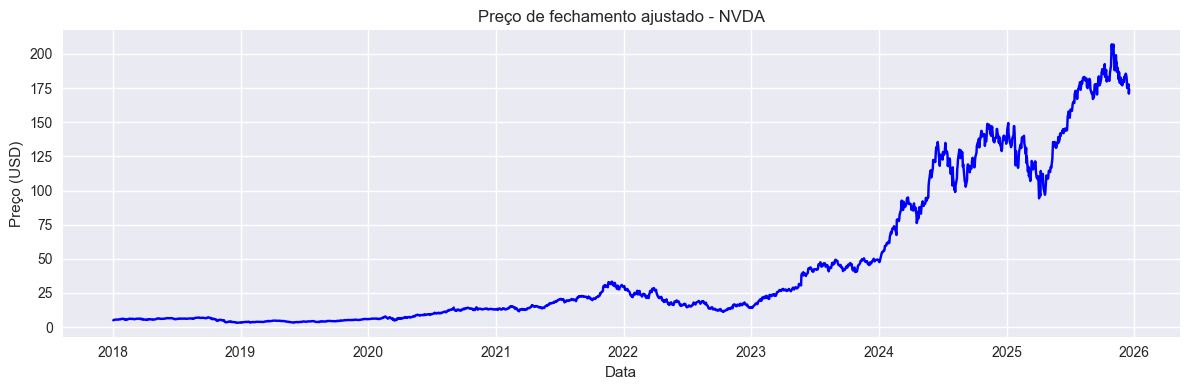

In [7]:
plt.figure(figsize=(12, 4))
plt.plot(df.index, df["close"], label="Adj Close", color="blue")
plt.title(f"Preço de fechamento ajustado - {TICKER}")
plt.xlabel("Data")
plt.ylabel("Preço (USD)")
plt.grid(True)
plt.tight_layout()
plt.show()

In [8]:
train = df.loc[:TRAIN_END]
val = df.loc[TRAIN_END:VAL_END]
test = df.loc[VAL_END:]

# Opcional: remover primeira linha das transições para evitar duplicação de dia
val = val.iloc[1:]
test = test.iloc[1:]

print("Tamanhos:")
print("Train:", train.shape)
print("Val:  ", val.shape)
print("Test: ", test.shape)

print("\nIntervalos reais:")
print("Train:", train.index.min().date(), "→", train.index.max().date())
print("Val:  ", val.index.min().date(), "→", val.index.max().date())
print("Test: ", test.index.min().date(), "→", test.index.max().date())

Tamanhos:
Train: (1259, 1)
Val:   (249, 1)
Test:  (493, 1)

Intervalos reais:
Train: 2018-01-02 → 2022-12-30
Val:   2023-01-04 → 2023-12-29
Test:  2024-01-03 → 2025-12-18


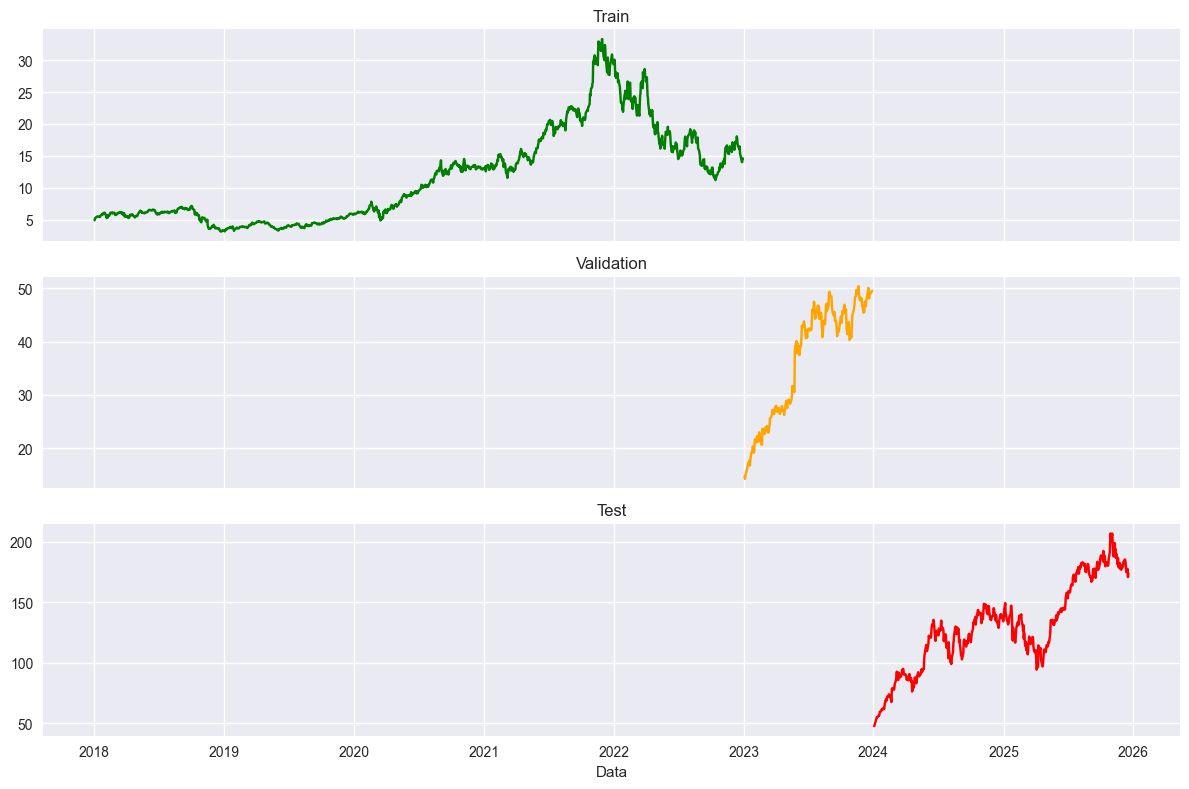

In [9]:
fig, axes = plt.subplots(3, 1, figsize=(12, 8), sharex=True)

axes[0].plot(train.index, train["close"], color="green")
axes[0].set_title("Train")

axes[1].plot(val.index, val["close"], color="orange")
axes[1].set_title("Validation")

axes[2].plot(test.index, test["close"], color="red")
axes[2].set_title("Test")

for ax in axes:
    ax.grid(True)

plt.xlabel("Data")
plt.tight_layout()
plt.show()

In [10]:
print("Etapa 2 concluída com sucesso! 🚀")
print("Dados prontos para criação das janelas (lookback).")

Etapa 2 concluída com sucesso! 🚀
Dados prontos para criação das janelas (lookback).
